## 1. Import the analysis libraries
Load the tools for data preparation, visualization, decision trees, and model evaluation.

In [1]:
# --- Guan: Import the analysis libraries ---
# AI-assisted code: No

# Load the libraries used throughout this lab.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn import tree
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.metrics import accuracy_score, confusion_matrix, mean_squared_error, r2_score

## 2. Load the UCI Bank Marketing dataset
Fetch the customer records, subscription outcomes, dataset metadata, and variable definitions.

In [2]:
# --- Guan: Load the UCI Bank Marketing dataset ---
# AI-assisted code: Yes


#look up csv file on my computer
!pip install ucimlrepo

from ucimlrepo import fetch_ucirepo

# fetch dataset
bank_marketing = fetch_ucirepo(id=222)

# data (as pandas dataframes)
X = bank_marketing.data.features
y = bank_marketing.data.targets

# metadata
print(bank_marketing.metadata)

# variable information
print(bank_marketing.variables)

{'uci_id': 222, 'name': 'Bank Marketing', 'repository_url': 'https://archive.ics.uci.edu/dataset/222/bank+marketing', 'data_url': 'https://archive.ics.uci.edu/static/public/222/data.csv', 'abstract': 'The data is related with direct marketing campaigns (phone calls) of a Portuguese banking institution. The classification goal is to predict if the client will subscribe a term deposit (variable y).', 'area': 'Business', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 45211, 'num_features': 16, 'feature_types': ['Categorical', 'Integer'], 'demographics': ['Age', 'Occupation', 'Marital Status', 'Education Level'], 'target_col': ['y'], 'index_col': None, 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 2014, 'last_updated': 'Fri Aug 18 2023', 'dataset_doi': '10.24432/C5K306', 'creators': ['S. Moro', 'P. Rita', 'P. Cortez'], 'intro_paper': {'ID': 277, 'type': 'NATIVE', 'title': 'A data-driven approach to predict the s

## 3. Combine predictors and subscription outcomes
Create one table and preview the first five customer records.

In [3]:
# --- Guan: Combine predictors and subscription outcomes ---
# AI-assisted code: No


#Show Data
bank_df = pd.concat([X, y], axis=1)
bank_df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,no


## 4. Inspect previous campaign outcomes
Check the recorded outcome categories and whether missing outcomes are present.

In [4]:
# --- Guan: Inspect previous campaign outcomes ---
# AI-assisted code: No

#find unique poutcome
bank_df.poutcome.unique()

array([nan, 'failure', 'other', 'success'], dtype=object)

## 5. Inspect data types and missing values
Review column types, record counts, and non-missing values before preparing the model inputs.

In [5]:
# --- Guan: Inspect data types and missing values ---
# AI-assisted code: No

bank_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   age          45211 non-null  int64 
 1   job          44923 non-null  object
 2   marital      45211 non-null  object
 3   education    43354 non-null  object
 4   default      45211 non-null  object
 5   balance      45211 non-null  int64 
 6   housing      45211 non-null  object
 7   loan         45211 non-null  object
 8   contact      32191 non-null  object
 9   day_of_week  45211 non-null  int64 
 10  month        45211 non-null  object
 11  duration     45211 non-null  int64 
 12  campaign     45211 non-null  int64 
 13  pdays        45211 non-null  int64 
 14  previous     45211 non-null  int64 
 15  poutcome     8252 non-null   object
 16  y            45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


## 6. Keep information available before initial targeting
Remove call duration, final campaign contact count, recorded contact date, and contact method for this prediction timing.

In [6]:
# --- Guan: Keep information available before initial targeting ---
# AI-assisted code: No

# drop columns "duration", "campaign", "day_of_week", "month", and "contact" since they
# are unknown before the call.
cols = ['duration','campaign','day_of_week','month','contact']
bank_df.drop(columns=cols, inplace=True)
bank_df

,age,job,marital,education,default,balance,housing,loan,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,-1,0,NaN,no
4,33,NaN,single,NaN,no,1,no,no,-1,0,NaN,no
...,...,...,...,...,...,...,...,...,...,...,...,...
45206,51,technician,married,tertiary,no,825,no,no,-1,0,NaN,yes
45207,71,retired,divorced,primary,no,1729,no,no,-1,0,NaN,yes
45208,72,retired,married,secondary,no,5715,no,no,184,3,success,yes
45209,57,blue-collar,married,secondary,no,668,no,no,-1,0,NaN,no


## 7. Recheck previous outcome categories
Confirm that previous campaign outcomes remain available after removing the current-campaign fields.

In [7]:
# --- Guan: Recheck Atrributes categories ---
# AI-assisted code: No

#unique poutcome
bank_df.poutcome.unique()

array([nan, 'failure', 'other', 'success'], dtype=object)

## 8. Handle missing history and encode categorical inputs
Convert yes/no fields to 0/1, distinguish no previous contact from unknown outcomes, and create dummy columns.

In [8]:
# --- Guan: Handle missing history and encode categorical inputs ---
# AI-assisted code: Yes

model_df = bank_df.copy()

# Convert binary columns directly to 0/1
binary_cols = ["default", "housing", "loan", "y"]

for col in binary_cols:
    model_df[col] = model_df[col].map({"no": 0, "yes": 1})

# Distinguish no previous contact from an unknown outcome
no_history = (
    model_df["poutcome"].isna()
    & model_df["previous"].eq(0)
)
model_df.loc[no_history, "poutcome"] = "no_previous_contact"

# Mark all remaining categorical predictors as categorical
cat_cols = [
    "job", "marital", "education", "poutcome"
]

for col in cat_cols:
    model_df[col] = (
        model_df[col]
        .fillna("unknown")
        .astype("category")
    )

# Create one dummy column per category
model_df = pd.get_dummies(
    model_df,
    prefix_sep="_",
    drop_first=False,
    dtype=int
)

model_df.head()

,age,default,balance,housing,loan,pdays,previous,y,job_admin.,job_blue-collar,...,marital_single,education_primary,education_secondary,education_tertiary,education_unknown,poutcome_failure,poutcome_no_previous_contact,poutcome_other,poutcome_success,poutcome_unknown
0,58,0,2143,1,0,-1,0,0,0,0,...,0,0,0,1,0,0,1,0,0,0
1,44,0,29,1,0,-1,0,0,0,0,...,1,0,1,0,0,0,1,0,0,0
2,33,0,2,1,1,-1,0,0,0,0,...,0,0,1,0,0,0,1,0,0,0
3,47,0,1506,1,0,-1,0,0,0,1,...,0,0,0,0,1,0,1,0,0,0
4,33,0,1,0,0,-1,0,0,0,0,...,1,0,0,0,1,0,1,0,0,0


## 9. Explore correlations with subscription
Rank pairwise correlations with the target as descriptive associations, rather than causal effects or a complete measure of predictive value.

In [9]:
# --- Guan: Explore correlations with subscription ---
# AI-assisted code: No


#find the correlation between each attributes to y
corr_matrix = model_df.corr()
corr_matrix["y"].sort_values(ascending=False)

,y
y,1.000000
poutcome_success,0.306788
pdays,0.103621
previous,0.093236
job_retired,0.079245
job_student,0.076897
education_tertiary,0.066448
marital_single,0.063526
balance,0.052838
job_management,0.032919


## 10. Verify the encoded data structure
Confirm the prepared columns have numerical types and inspect their non-missing record counts.

In [10]:
# --- Guan: Verify the encoded data structure ---
# AI-assisted code: No


#see if categorical values are adjusted in model data
model_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 32 columns):
 #   Column                        Non-Null Count  Dtype
---  ------                        --------------  -----
 0   age                           45211 non-null  int64
 1   default                       45211 non-null  int64
 2   balance                       45211 non-null  int64
 3   housing                       45211 non-null  int64
 4   loan                          45211 non-null  int64
 5   pdays                         45211 non-null  int64
 6   previous                      45211 non-null  int64
 7   y                             45211 non-null  int64
 8   job_admin.                    45211 non-null  int64
 9   job_blue-collar               45211 non-null  int64
 10  job_entrepreneur              45211 non-null  int64
 11  job_housemaid                 45211 non-null  int64
 12  job_management                45211 non-null  int64
 13  job_retired                   4

## 11. Separate predictors from the target
Use the customer attributes as X and the subscription outcome as y.

In [11]:
# --- Guan: Separate predictors from the target ---
# AI-assisted code: No


# Separate predictors and target
X = model_df.drop(columns="y")
y = model_df["y"]

model_df.head()

,age,default,balance,housing,loan,pdays,previous,y,job_admin.,job_blue-collar,...,marital_single,education_primary,education_secondary,education_tertiary,education_unknown,poutcome_failure,poutcome_no_previous_contact,poutcome_other,poutcome_success,poutcome_unknown
0,58,0,2143,1,0,-1,0,0,0,0,...,0,0,0,1,0,0,1,0,0,0
1,44,0,29,1,0,-1,0,0,0,0,...,1,0,1,0,0,0,1,0,0,0
2,33,0,2,1,1,-1,0,0,0,0,...,0,0,1,0,0,0,1,0,0,0
3,47,0,1506,1,0,-1,0,0,0,1,...,0,0,0,0,1,0,1,0,0,0
4,33,0,1,0,0,-1,0,0,0,0,...,1,0,0,0,1,0,1,0,0,0


## 12. Validate the model inputs
Check that predictors are numeric and complete, and that the target contains both binary classes.

In [12]:
# --- Guan: Validate the model inputs ---
# AI-assisted code: Yes


# Check the data before modeling
assert X.select_dtypes(exclude=["number", "bool"]).empty
assert not X.isna().any().any()
assert y.isin([0, 1]).all()
assert y.nunique() == 2

## 13. Create stratified training and test sets
Reserve 40% of records for testing and keep the subscriber proportion approximately consistent across both sets.

In [13]:
# --- Guan: Create stratified training and test sets ---
# AI-assisted code: No


# Split into 60% training and 40% testing, exactly as in class
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.4, random_state=1, stratify=y
)

## 14. Train the initial decision tree
Fit a tree with a maximum depth of 3 and at least 100 training records per leaf.

In [27]:
# --- Guan: Train the initial decision tree ---
# AI-assisted code: No

# Grow the full tree without additional depth or leaf-size restrictions.
full_clf = DecisionTreeClassifier(
    max_depth=5,
    min_samples_leaf=20,
    min_impurity_decrease=0.0005,
    random_state=1
)
full_clf.fit(X_train, y_train)

print("Number of nodes:", full_clf.tree_.node_count)
print("Tree depth:", full_clf.get_depth())

Number of nodes: 11
Tree depth: 5


## 15. Visualize the initial decision tree
Display the learned splits and leaf groups to inspect how the tree separates customers. (parameter settings are from grid search)

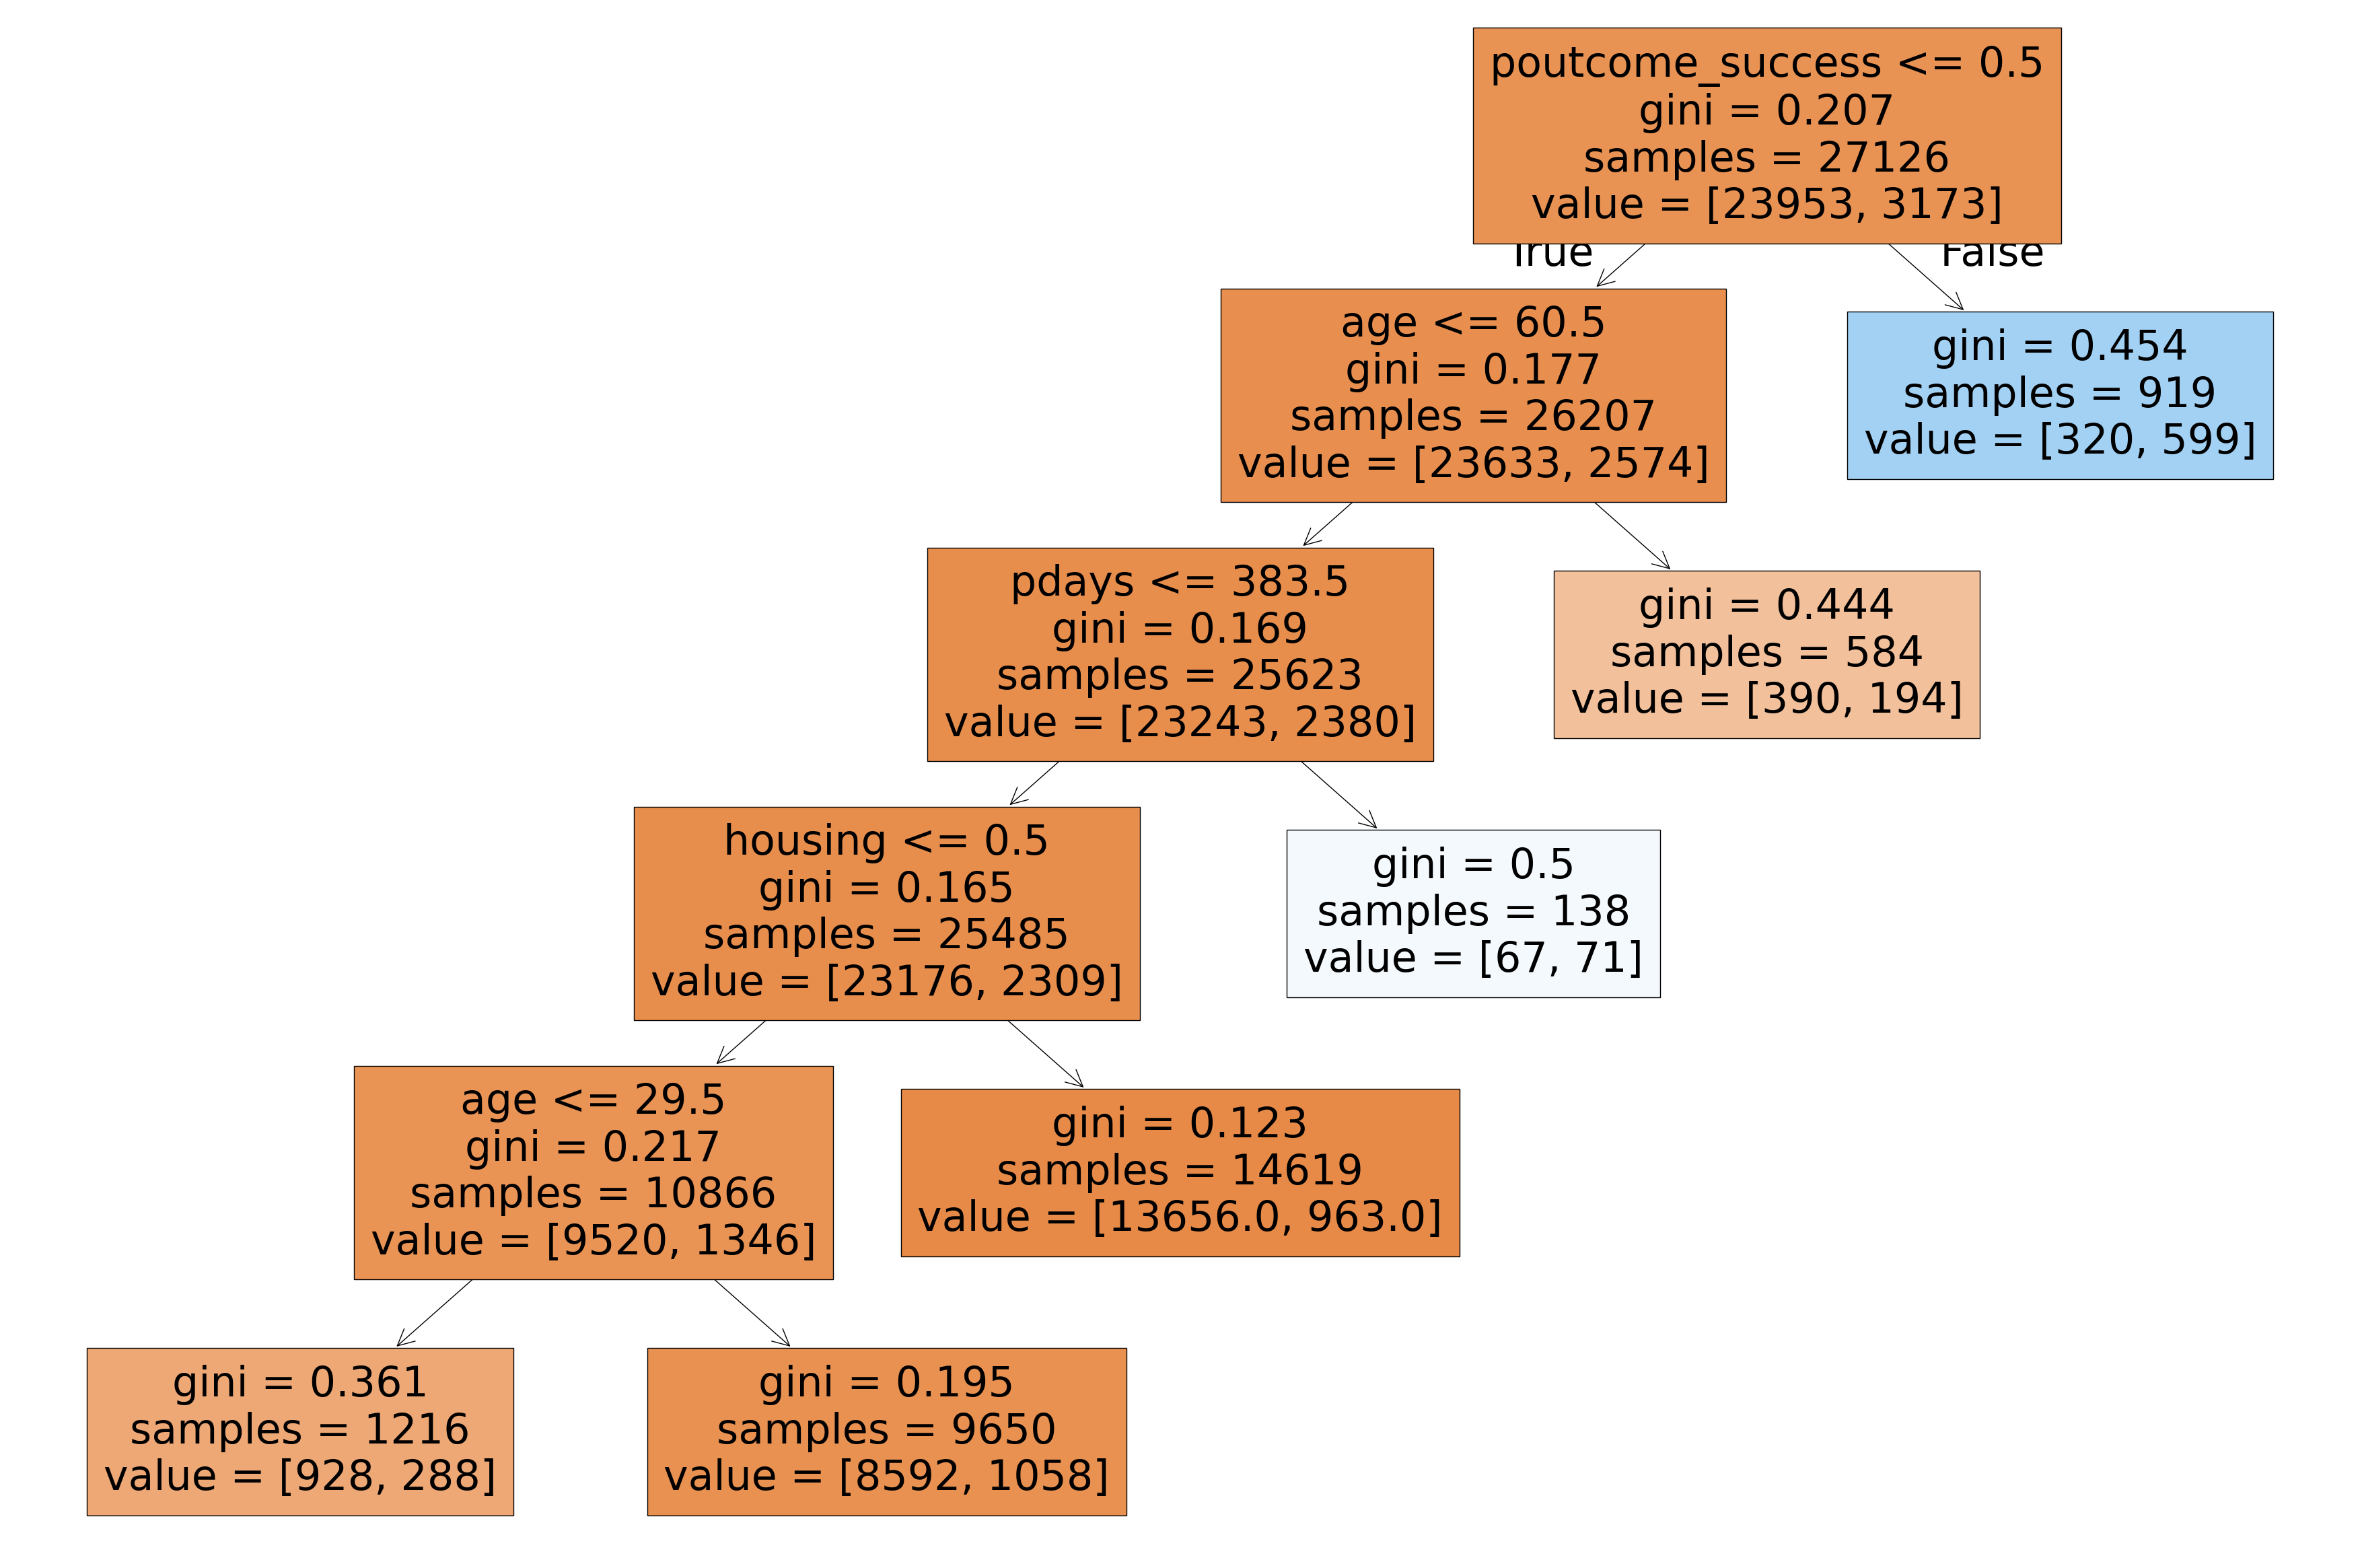

In [28]:
# --- Guan: Visualize the initial decision tree ---
# AI-assisted code: No

# Draw the full tree; 'filled' colors each node by majority class.
plt.figure(figsize=(45, 30))
tree.plot_tree(full_clf, feature_names=X.columns, filled=True);

## 16. Generate training and test predictions
Apply the fitted initial tree separately to the training records and held-out test customers.

In [17]:
# --- Guan: Generate training and test predictions ---
# AI-assisted code: Yes

# Predict subscription for the training and test customers separately.
y_pred_train = full_clf.predict(X_train)
y_pred_test = full_clf.predict(X_test)

## 17. Compare training and test accuracy
Check performance on both sets, remembering that class imbalance can make accuracy look high.

In [18]:
# --- Guan: Compare training and test accuracy ---
# AI-assisted code: Yes

# Accuracy of the full tree on training and test sets.
train_score = accuracy_score(y_train, y_pred_train)
test_score = accuracy_score(y_test, y_pred_test)

print(
    "Accuracy score of full tree on training data =",
    round(train_score * 100, 1),
    "%"
)
print(
    "Accuracy score of full tree on testing data =",
    round(test_score * 100, 1),
    "%"
)

Accuracy score of full tree on training data = 89.4 %
Accuracy score of full tree on testing data = 89.1 %


## 18. Count correct predictions and classification errors
Use confusion matrices to distinguish subscribers found, subscribers missed, and non-subscribers selected.

In [19]:
# --- Guan: Count correct predictions and classification errors ---
# AI-assisted code: Yes

# Confusion matrices of the full tree on the training and test sets.
print("Confusion Matrix of full tree on train data:")
print(confusion_matrix(y_train, y_pred_train))

print("Confusion Matrix of full tree on test data:")
print(confusion_matrix(y_test, y_pred_test))

Confusion Matrix of full tree on train data:
[[23637   316]
 [ 2563   610]]
Confusion Matrix of full tree on test data:
[[15756   213]
 [ 1751   365]]


## 19. Visualize prediction scores and the default cutoff
Compare each test customer’s subscription score with the actual outcome and the 50% selection threshold.

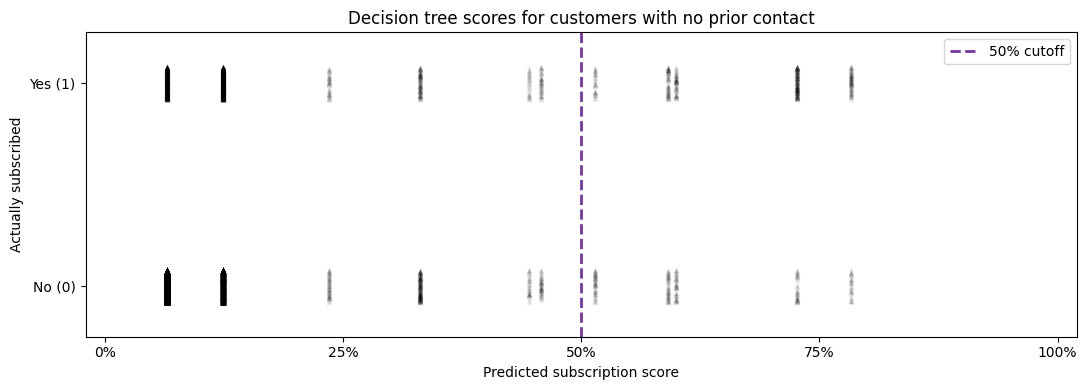

In [20]:
# --- Guan: Visualize prediction scores and the default cutoff ---
# AI-assisted code: Yes

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter

cutoff = 0.50

plot_data = pd.DataFrame({
    "score": full_clf.predict_proba(X_test)[:, 1],
    "actual": y_test.loc[X_test.index].to_numpy(),
})

# Add a little vertical spacing so tied scores are visible.
# The scores on the x-axis stay exactly as the tree predicted them.
rng = np.random.default_rng(42)
plot_data["plot_y"] = plot_data["actual"] + rng.uniform(
    -0.08, 0.08, size=len(plot_data)
)

fig, ax = plt.subplots(figsize=(11, 4))

ax.scatter(
    plot_data["score"],
    plot_data["plot_y"],
    marker="^",
    color="black",
    s=16,
    alpha=0.08,
    linewidths=0,
)

ax.axvline(
    cutoff, color="#7534a5", linestyle="--", linewidth=2,
    label=f"{cutoff:.0%} cutoff",
)

ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.25, 1.25)
ax.set_xticks([0, 0.25, 0.50, 0.75, 1])
ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.set_yticks([0, 1], labels=["No (0)", "Yes (1)"])
ax.set_xlabel("Predicted subscription score")
ax.set_ylabel("Actually subscribed")
ax.set_title("Decision tree scores for customers with no prior contact")
ax.legend()
plt.tight_layout()
plt.show()

## 20. Summarize precision, recall, F1, and selection rate
Compare initial-tree training and test metrics to assess subscriber detection and the size of the proposed call list.

In [21]:
# --- Guan: Summarize precision, recall, F1, and selection rate ---
# AI-assisted code: Yes

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix, roc_curve, roc_auc_score
)
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.base import clone

def evaluate_predictions(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    def divide(a, b):
        return a / b if b else 0.0

    return {
        "Accuracy": divide(tp + tn, tp + tn + fp + fn),
        "Precision": divide(tp, tp + fp),
        "Recall / TPR": divide(tp, tp + fn),
        "FPR": divide(fp, fp + tn),
        "Specificity": divide(tn, tn + fp),
        "F1": divide(2 * tp, 2 * tp + fp + fn),
        "Selected fraction": divide(tp + fp, tp + tn + fp + fn)
    }

current_results = pd.DataFrame({
    "Training": evaluate_predictions(y_train, y_pred_train),
    "Test": evaluate_predictions(y_test, y_pred_test)
}).T

# Display metrics as percentages
(current_results * 100).round(2)

,Accuracy,Precision,Recall / TPR,FPR,Specificity,F1,Selected fraction
Training,89.39,65.87,19.22,1.32,98.68,29.76,3.41
Test,89.14,63.15,17.25,1.33,98.67,27.10,3.20


## 21. Set up the random forest comparison
Import the ensemble classifier for comparison with a single decision tree.

In [30]:
# --- Guan: Set up the random forest comparison ---
# AI-assisted code: No

# Load the random forest classifier.
from sklearn.ensemble import RandomForestClassifier

## 22. Train a random forest with 500 trees
Fit multiple trees using bootstrap samples and random feature subsets.

In [31]:
# --- Guan: Train a random forest with 500 trees ---
# AI-assisted code: No

# Grow 500 trees using bootstrap samples of customers
# and random subsets of features at each split.
rf = RandomForestClassifier(
    n_estimators=500,  # number of trees in the forest
    random_state=0,
    criterion="gini",
    n_jobs=-1         # use every available CPU core
)

rf.fit(X_train, y_train)

RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=0)

## 23. Tune random forest settings with cross-validation
Use randomized search on the training data to compare settings and select the highest average F1.

In [32]:
# --- Guan: Tune random forest settings with cross-validation ---
# AI-assisted code: Yes


from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedKFold
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=1
)

parameter_options = {
    "max_depth": [5, 10, 20, None],
    "min_samples_leaf": [5, 20, 50],
    "max_features": ["sqrt", 0.5],
    "class_weight": [None, "balanced", "balanced_subsample"]
}

# Search several models in parallel.
# Each individual forest uses one CPU core to avoid nested parallelism.
search = RandomizedSearchCV(
    estimator=RandomForestClassifier(
        n_estimators=500,
        random_state=0,
        n_jobs=1
    ),
    param_distributions=parameter_options,
    n_iter=12,             # Test 12 combinations
    scoring="f1",
    cv=cv,
    random_state=1,
    n_jobs=-1,
    verbose=1,
    refit=True
)

search.fit(X_train, np.asarray(y_train).ravel())

print("Selected settings:")
print(search.best_params_)

print(f"\nBest average cross-validation F1: {search.best_score_:.2%}")

# Use this tuned forest in your existing cutoff-selection code.
rf = search.best_estimator_
rf.set_params(n_jobs=-1)

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Selected settings:
{'min_samples_leaf': 20, 'max_features': 0.5, 'max_depth': 20, 'class_weight': 'balanced'}

Best average cross-validation F1: 38.84%


RandomForestClassifier(class_weight='balanced', max_depth=20, max_features=0.5,
                       min_samples_leaf=20, n_estimators=500, n_jobs=-1,
                       random_state=0)

## 24. Choose a random forest cutoff and evaluate it
Use out-of-fold training scores to select a cutoff, then compare default and selected cutoffs on the held-out test set.

In [33]:
# --- Guan: Choose a random forest cutoff and evaluate it ---
# AI-assisted code: Yes

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (
    precision_recall_curve,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Assumes the target is coded: subscriber = 1, non-subscriber = 0.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)

# Each training customer gets a score from a forest that did not train on them.
# Run folds sequentially because each forest already uses all CPU cores.
oof_probs = cross_val_predict(
    clone(rf),
    X_train,
    np.asarray(y_train).ravel(),
    cv=cv,
    method="predict_proba",
    n_jobs=1
)[:, 1]

# Calculate F1 at every available cutoff.
precisions, recalls, thresholds = precision_recall_curve(
    np.asarray(y_train).ravel(), oof_probs
)

# The last precision/recall point has no corresponding threshold.
denominator = precisions[:-1] + recalls[:-1]
f1_scores = np.divide(
    2 * precisions[:-1] * recalls[:-1],
    denominator,
    out=np.zeros_like(denominator),
    where=denominator > 0
)

best_index = np.argmax(f1_scores)
best_cutoff = thresholds[best_index]

print(f"Selected cutoff: {best_cutoff:.6f}")
print(f"Cross-validation F1: {f1_scores[best_index]:.2%}")

# Refit on all training records, then evaluate on the held-out test set.
rf.fit(X_train, np.asarray(y_train).ravel())
test_probs = rf.predict_proba(X_test)[:, 1]

results = []

for label, cutoff in [
    ("Default cutoff", 0.50),
    ("Selected cutoff", best_cutoff)
]:
    predictions = (test_probs >= cutoff).astype(int)

    results.append({
        "Approach": label,
        "Cutoff": cutoff,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "Customers selected": int(predictions.sum())
    })

    print(f"\n{label} confusion matrix:")
    print(confusion_matrix(y_test, predictions, labels=[0, 1]))

comparison = pd.DataFrame(results).set_index("Approach")

display(comparison.style.format({
    "Cutoff": "{:.6f}",
    "Accuracy": "{:.2%}",
    "Precision": "{:.2%}",
    "Recall": "{:.2%}",
    "F1": "{:.2%}",
    "Customers selected": "{:,.0f}"
}))

Selected cutoff: 0.598892
Cross-validation F1: 40.10%

Default cutoff confusion matrix:
[[13857  2112]
 [ 1098  1018]]

Selected cutoff confusion matrix:
[[14846  1123]
 [ 1307   809]]


,Cutoff,Accuracy,Precision,Recall,F1,Customers selected
Approach,,,,,,
Default cutoff,0.500000,82.25%,32.52%,48.11%,38.81%,"3,130"
Selected cutoff,0.598892,86.56%,41.87%,38.23%,39.97%,"1,932"


## 24. Random forest detection between groups (Previous Success vs. no Previous Success)



Same random forest, same cutoff: 0.598892


,Test customers,Actual subscribers,Subscription rate,Customers selected,Selection rate,Subscribers found,Non-subscribers selected,Subscribers missed,Precision,Recall,F1
Group,,,,,,,,,,,
No previous success,17493,1737,9.93%,1340,7.66%,430,910,1307,32.09%,24.76%,27.95%
Previous success,592,379,64.02%,592,100.00%,379,213,0,64.02%,100.00%,78.06%


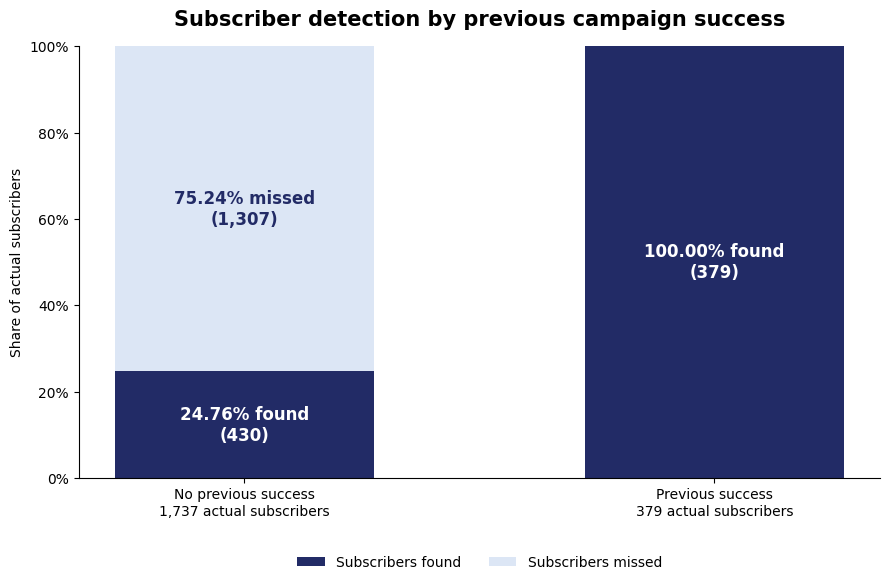

In [35]:
#compare forest results by previous campaign success
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_score, recall_score, f1_score, confusion_matrix
)
from matplotlib.ticker import PercentFormatter

# Match original customer records to the test set.
# bank_df must be the original full dataset with unchanged indexes.
if not X_test.index.is_unique or not bank_df.index.is_unique:
    raise ValueError("Customer indexes must be unique.")

if not X_test.index.isin(bank_df.index).all():
    raise ValueError("Use the original full bank_df with unchanged indexes.")

previous_outcome = (
    bank_df.loc[X_test.index, "poutcome"]
    .astype("string")
    .str.strip()
    .str.lower()
)

groups = np.where(
    previous_outcome.eq("success").fillna(False).to_numpy(dtype=bool),
    "Previous success",
    "No previous success"
)

# Align test outcomes.
if isinstance(y_test, (pd.Series, pd.DataFrame)):
    actual = np.asarray(y_test.loc[X_test.index]).ravel()
else:
    actual = np.asarray(y_test).ravel()

# Apply the existing forest and exact selected cutoff.
positive_column = list(rf.classes_).index(1)
scores = rf.predict_proba(X_test)[:, positive_column]
predicted = (scores >= best_cutoff).astype(int)

results = pd.DataFrame({
    "Group": groups,
    "Actual": actual,
    "Predicted": predicted
}, index=X_test.index)

# Calculate group results.
rows = []

for group, data in results.groupby("Group"):
    tn, fp, fn, tp = confusion_matrix(
        data["Actual"], data["Predicted"], labels=[0, 1]
    ).ravel()

    rows.append({
        "Group": group,
        "Test customers": len(data),
        "Actual subscribers": int(tp + fn),
        "Subscription rate": data["Actual"].mean(),
        "Customers selected": int(tp + fp),
        "Selection rate": data["Predicted"].mean(),
        "Subscribers found": int(tp),
        "Non-subscribers selected": int(fp),
        "Subscribers missed": int(fn),
        "Precision": tp / (tp + fp) if tp + fp else np.nan,
        "Recall": tp / (tp + fn) if tp + fn else np.nan,
        "F1": (
            2 * tp / (2 * tp + fp + fn)
            if 2 * tp + fp + fn else np.nan
        )
    })

success_comparison = (
    pd.DataFrame(rows)
    .set_index("Group")
    .loc[["No previous success", "Previous success"]]
)

print(f"Same random forest, same cutoff: {best_cutoff:.6f}")

display(success_comparison.style.format({
    "Subscription rate": "{:.2%}",
    "Selection rate": "{:.2%}",
    "Precision": "{:.2%}",
    "Recall": "{:.2%}",
    "F1": "{:.2%}"
}, na_rep="N/A"))

# Plot the share of actual subscribers found versus missed.
found = success_comparison["Subscribers found"].to_numpy()
missed = success_comparison["Subscribers missed"].to_numpy()
totals = found + missed

if (totals == 0).any():
    print("Chart skipped: one group contains no actual subscribers.")
else:
    found_pct = found / totals * 100
    missed_pct = missed / totals * 100
    x = np.arange(len(success_comparison))

    fig, ax = plt.subplots(figsize=(9, 6))

    ax.bar(
        x, found_pct, width=0.55,
        color="#222B66", label="Subscribers found"
    )
    ax.bar(
        x, missed_pct, bottom=found_pct, width=0.55,
        color="#DCE6F5", label="Subscribers missed"
    )

    for i in range(len(x)):
        if found[i] > 0:
            ax.text(
                i, found_pct[i] / 2,
                f"{found_pct[i]:.2f}% found\n({found[i]:,})",
                ha="center", va="center",
                color="white", fontweight="bold", fontsize=12
            )
        if missed[i] > 0:
            ax.text(
                i, found_pct[i] + missed_pct[i] / 2,
                f"{missed_pct[i]:.2f}% missed\n({missed[i]:,})",
                ha="center", va="center",
                color="#222B66", fontweight="bold", fontsize=12
            )

    ax.set_xticks(x)
    ax.set_xticklabels([
        f"{group}\n{total:,} actual subscribers"
        for group, total in zip(success_comparison.index, totals)
    ])
    ax.set_ylim(0, 100)
    ax.yaxis.set_major_formatter(PercentFormatter(100))
    ax.set_ylabel("Share of actual subscribers")
    ax.set_title(
        "Subscriber detection by previous campaign success",
        fontsize=15, fontweight="bold", pad=15
    )
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(
        loc="upper center", bbox_to_anchor=(0.5, -0.15),
        ncol=2, frameon=False
    )

    fig.tight_layout()
    fig.savefig(
        "recall_by_previous_success.png",
        dpi=300, bbox_inches="tight"
    )
    plt.show()

## 25. Count subscribers found and missed by contact history
Apply the same fitted forest and selected cutoff to customers with and without previous contact.

In [ ]:
# --- Guan: Count subscribers found and missed by contact history ---
# AI-assisted code: Yes

# bank_df must be the original full dataset with unchanged row indexes.
if not X_test.index.is_unique or not bank_df.index.is_unique:
    raise ValueError("Customer row indexes must be unique.")

if not X_test.index.isin(bank_df.index).all():
    raise ValueError("Use the original full bank_df with unchanged indexes.")

# Recover original, unscaled previous-contact counts.
previous = pd.to_numeric(
    bank_df.loc[X_test.index, "previous"],
    errors="coerce"
)

if previous.isna().any() or (previous < 0).any():
    raise ValueError("Use the original, unscaled 'previous' column.")

# Align actual outcomes with test customers.
if isinstance(y_test, (pd.Series, pd.DataFrame)):
    actual = np.asarray(y_test.loc[X_test.index]).ravel()
else:
    actual = np.asarray(y_test).ravel()

# Use the existing fitted forest and exact selected cutoff.
positive_column = list(rf.classes_).index(1)
scores = rf.predict_proba(X_test)[:, positive_column]
selected = (scores >= best_cutoff).astype(int)

contact_results = pd.DataFrame({
    "Group": np.where(
        previous.to_numpy() > 0,
        "Previously contacted",
        "No previous contact"
    ),
    "Actual": actual,
    "Selected": selected
})

contact_results["Subscribers found"] = (
    (contact_results["Actual"] == 1) &
    (contact_results["Selected"] == 1)
).astype(int)

contact_results["Subscribers missed"] = (
    (contact_results["Actual"] == 1) &
    (contact_results["Selected"] == 0)
).astype(int)

contact_comparison = contact_results.groupby("Group")[
    ["Subscribers found", "Subscribers missed"]
].sum()

display(contact_comparison)

,Subscribers found,Subscribers missed
Group,,
No previous contact,261,1089
Previously contacted,548,218


## 26. Visualize subscriber detection by previous contact
Plot the share of actual subscribers found and missed in each contact-history group.

In [29]:
# --- Guan: Visualize subscriber detection by previous contact ---
# AI-assisted code: Yes

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

groups = ["No previous contact", "Previously contacted"]
data = contact_comparison.loc[groups]

found = data["Subscribers found"].to_numpy()
missed = data["Subscribers missed"].to_numpy()
totals = found + missed

if (totals == 0).any():
    raise ValueError("Each group must contain actual subscribers.")

found_pct = found / totals * 100
missed_pct = missed / totals * 100
x = np.arange(len(groups))

fig, ax = plt.subplots(figsize=(9, 6))

ax.bar(
    x, found_pct,
    color="#222B66", width=0.55,
    label="Subscribers found"
)
ax.bar(
    x, missed_pct, bottom=found_pct,
    color="#DCE6F5", width=0.55,
    label="Subscribers missed"
)

for i in range(len(groups)):
    ax.text(
        i, found_pct[i] / 2,
        f"{found_pct[i]:.2f}% found\n({found[i]:,})",
        ha="center", va="center",
        color="white", fontsize=13, fontweight="bold"
    )
    ax.text(
        i, found_pct[i] + missed_pct[i] / 2,
        f"{missed_pct[i]:.2f}% missed\n({missed[i]:,})",
        ha="center", va="center",
        color="#222B66", fontsize=13, fontweight="bold"
    )

ax.set_xticks(x)
ax.set_xticklabels([
    f"{group}\n{total:,} actual subscribers"
    for group, total in zip(groups, totals)
])

ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(PercentFormatter(100))
ax.set_ylabel("Share of actual subscribers")
ax.set_title(
    "Subscriber detection by previous contact status",
    fontsize=16, fontweight="bold", pad=18
)
ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.15),
    ncol=2, frameon=False
)
ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()

# Save a presentation-ready image in Colab.
fig.savefig(
    "recall_by_previous_contact.png",
    dpi=300, bbox_inches="tight"
)
plt.show()

print("Same model and cutoff used for both groups.")
for group, recall in zip(groups, found_pct):
    print(f"{group}: recall = {recall:.2f}%")

NameError: name 'contact_comparison' is not defined

## 27. Evaluate the forest across customer groups
Compare precision, recall, F1, and selection rates by housing-loan status, previous contact, and education.

In [ ]:
# --- Guan: Evaluate the forest across customer groups ---
# AI-assisted code: Yes

import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_score, recall_score, f1_score, confusion_matrix
)

# Check that original customer information can be matched to the test set.
if not X_test.index.is_unique or not bank_df.index.is_unique:
    raise ValueError("Customer row indexes must be unique.")

if not X_test.index.isin(bank_df.index).all():
    raise ValueError("Use the original full bank_df with unchanged row indexes.")

raw_test = bank_df.loc[
    X_test.index, ["housing", "previous", "education"]
].copy()

# Prepare housing-loan groups.
housing_group = raw_test["housing"].replace({
    "yes": "Housing loan",
    "no": "No housing loan",
    1: "Housing loan",
    0: "No housing loan"
})

if not housing_group.isin(
    ["Housing loan", "No housing loan"]
).all():
    raise ValueError("The original housing column must contain yes/no or 0/1.")

# Prepare previous-contact groups.
previous = pd.to_numeric(raw_test["previous"], errors="coerce")

if previous.isna().any() or (previous < 0).any():
    raise ValueError("Use the original, unscaled previous-contact counts.")

contact_group = pd.Series(
    np.where(
        previous > 0,
        "Previously contacted",
        "No previous contact"
    ),
    index=X_test.index
)

# Prepare education groups, retaining missing values.
education_group = (
    raw_test["education"]
    .fillna("unknown")
    .astype(str)
    .str.strip()
    .str.lower()
)

# Align actual outcomes with the test customers.
if isinstance(y_test, (pd.Series, pd.DataFrame)):
    actual = np.asarray(y_test.loc[X_test.index]).ravel()
else:
    actual = np.asarray(y_test).ravel()

# Generate predictions once, using the existing fitted forest.
cutoff = best_cutoff
positive_column = list(rf.classes_).index(1)
scores = rf.predict_proba(X_test)[:, positive_column]
predictions = (scores >= cutoff).astype(int)

test_results = pd.DataFrame({
    "Actual": actual,
    "Selected": predictions
}, index=X_test.index)


def compare_groups(group_labels):
    """Evaluate the same predictions separately within each group."""
    data = test_results.copy()
    data["Group"] = group_labels
    rows = []

    for group, subset in data.groupby("Group"):
        y_actual = subset["Actual"]
        y_selected = subset["Selected"]

        tn, fp, fn, tp = confusion_matrix(
            y_actual, y_selected, labels=[0, 1]
        ).ravel()

        # Undefined metrics remain N/A rather than being displayed as zero.
        precision = (
            precision_score(y_actual, y_selected, zero_division=0)
            if tp + fp > 0 else np.nan
        )
        recall = (
            recall_score(y_actual, y_selected, zero_division=0)
            if tp + fn > 0 else np.nan
        )
        f1 = (
            f1_score(y_actual, y_selected, zero_division=0)
            if 2 * tp + fp + fn > 0 else np.nan
        )

        rows.append({
            "Group": group,
            "Test customers": len(subset),
            "Actual subscribers": int(tp + fn),
            "Subscription rate": y_actual.mean(),
            "Customers selected": int(tp + fp),
            "Selection rate": y_selected.mean(),
            "Subscribers found": int(tp),
            "Non-subscribers selected": int(fp),
            "Subscribers missed": int(fn),
            "Precision": precision,
            "Recall": recall,
            "F1": f1
        })

    return pd.DataFrame(rows).set_index("Group")


# Save each comparison so you can reuse it for charts.
housing_comparison = compare_groups(housing_group)
contact_comparison = compare_groups(contact_group)
education_comparison = compare_groups(education_group)

percent_format = {
    column: "{:.2%}"
    for column in [
        "Subscription rate", "Selection rate",
        "Precision", "Recall", "F1"
    ]
}

print(f"Same fitted random forest, same cutoff: {cutoff:.6f}")

for title, table in [
    ("HOUSING-LOAN STATUS", housing_comparison),
    ("PREVIOUS CONTACT STATUS", contact_comparison),
    ("EDUCATION", education_comparison)
]:
    print(f"\n{title}")
    display(table.style.format(percent_format, na_rep="N/A"))

Same fitted random forest, same cutoff: 0.598892

HOUSING-LOAN STATUS


,Test customers,Actual subscribers,Subscription rate,Customers selected,Selection rate,Subscribers found,Non-subscribers selected,Subscribers missed,Precision,Recall,F1
Group,,,,,,,,,,,
Housing loan,10137,787,7.76%,245,2.42%,124,121,663,50.61%,15.76%,24.03%
No housing loan,7948,1329,16.72%,1687,21.23%,685,1002,644,40.60%,51.54%,45.42%



PREVIOUS CONTACT STATUS


,Test customers,Actual subscribers,Subscription rate,Customers selected,Selection rate,Subscribers found,Non-subscribers selected,Subscribers missed,Precision,Recall,F1
Group,,,,,,,,,,,
No previous contact,14738,1350,9.16%,809,5.49%,261,548,1089,32.26%,19.33%,24.18%
Previously contacted,3347,766,22.89%,1123,33.55%,548,575,218,48.80%,71.54%,58.02%



EDUCATION


,Test customers,Actual subscribers,Subscription rate,Customers selected,Selection rate,Subscribers found,Non-subscribers selected,Subscribers missed,Precision,Recall,F1
Group,,,,,,,,,,,
primary,2783,233,8.37%,224,8.05%,90,134,143,40.18%,38.63%,39.39%
secondary,9291,988,10.63%,749,8.06%,322,427,666,42.99%,32.59%,37.08%
tertiary,5294,791,14.94%,840,15.87%,340,500,451,40.48%,42.98%,41.69%
unknown,717,104,14.50%,119,16.60%,57,62,47,47.90%,54.81%,51.12%


## 28. Visualize performance and errors across groups
Chart precision and recall, subscription and selection rates, and subscriber counts found and missed.

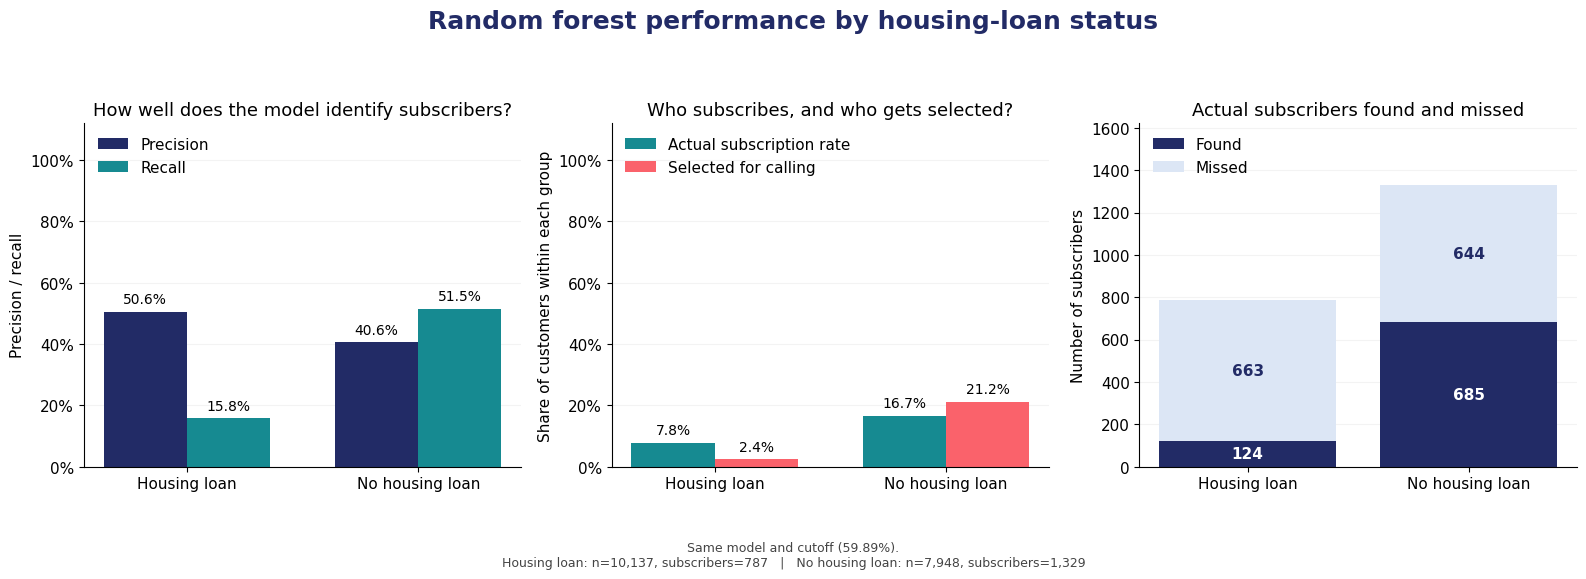

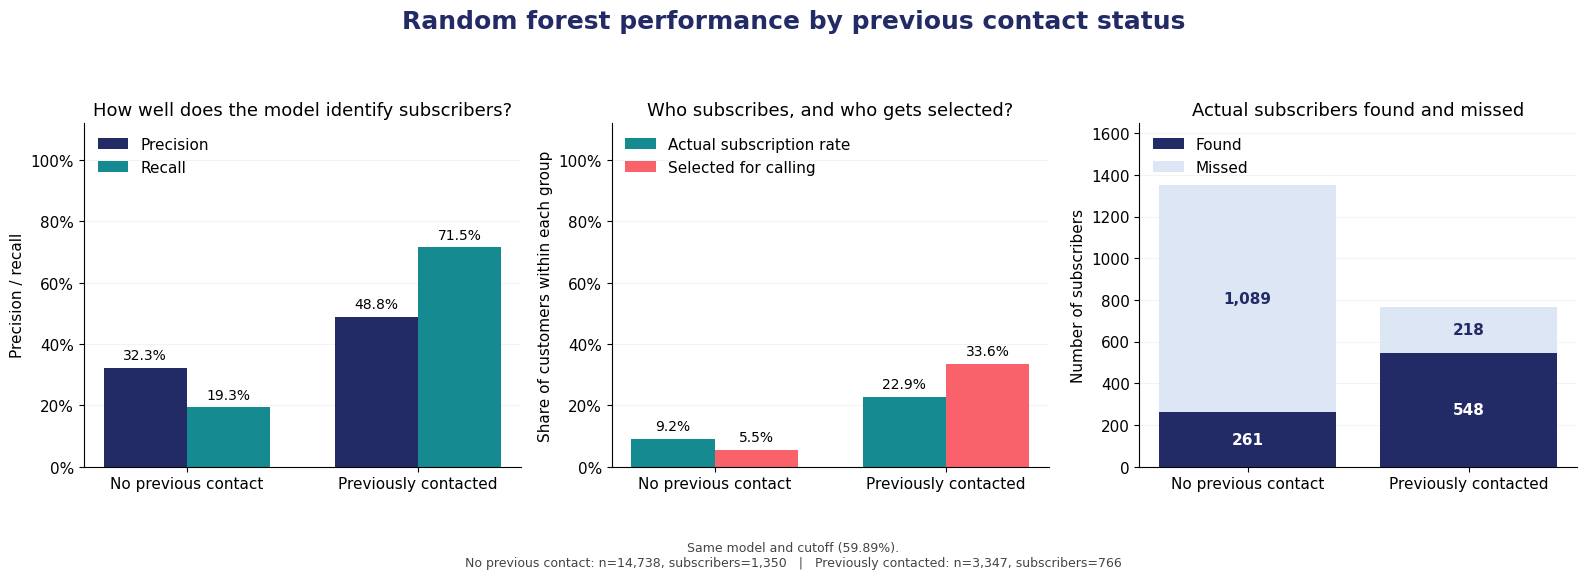

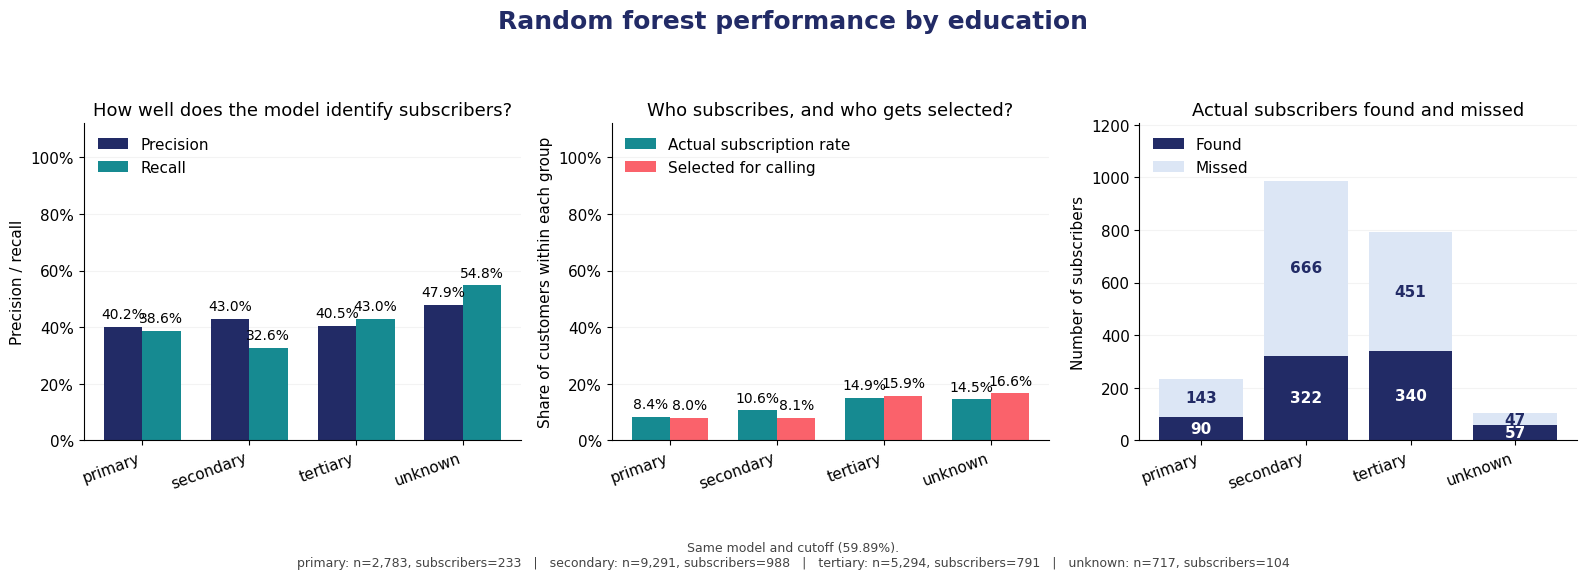

In [ ]:
# --- Guan: Visualize performance and errors across groups ---
# AI-assisted code: Yes

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11
})

NAVY = "#222B66"
TEAL = "#168A91"
CORAL = "#FA626B"
LIGHT = "#DCE6F5"


def graph_group_results(table, title):
    labels = table.index.astype(str).tolist()
    x = np.arange(len(labels))
    width = 0.36

    fig, axes = plt.subplots(
        1, 3,
        figsize=(max(16, len(labels) * 3), 5.8)
    )

    # 1. Precision and recall
    for offset, metric, color in [
        (-width / 2, "Precision", NAVY),
        (width / 2, "Recall", TEAL)
    ]:
        values = table[metric].to_numpy(dtype=float)
        bars = axes[0].bar(
            x + offset, values, width,
            label=metric, color=color
        )
        axes[0].bar_label(
            bars,
            labels=[
                f"{v:.1%}" if np.isfinite(v) else "N/A"
                for v in values
            ],
            padding=4,
            fontsize=10
        )

    axes[0].set_title("How well does the model identify subscribers?")
    axes[0].set_ylabel("Precision / recall")
    axes[0].set_ylim(0, 1.12)
    axes[0].yaxis.set_major_formatter(PercentFormatter(1))
    axes[0].legend(frameon=False, loc="upper left")

    # 2. Actual subscription rate and model selection rate
    for offset, metric, label, color in [
        (-width / 2, "Subscription rate",
         "Actual subscription rate", TEAL),
        (width / 2, "Selection rate",
         "Selected for calling", CORAL)
    ]:
        values = table[metric].to_numpy(dtype=float)
        bars = axes[1].bar(
            x + offset, values, width,
            label=label, color=color
        )
        axes[1].bar_label(
            bars,
            labels=[f"{v:.1%}" for v in values],
            padding=4,
            fontsize=10
        )

    axes[1].set_title("Who subscribes, and who gets selected?")
    axes[1].set_ylabel("Share of customers within each group")
    axes[1].set_ylim(0, 1.12)
    axes[1].yaxis.set_major_formatter(PercentFormatter(1))
    axes[1].legend(frameon=False, loc="upper left")

    # 3. Actual subscribers found and missed
    found = table["Subscribers found"].to_numpy()
    missed = table["Subscribers missed"].to_numpy()

    axes[2].bar(x, found, color=NAVY, label="Found")
    axes[2].bar(
        x, missed, bottom=found,
        color=LIGHT, label="Missed"
    )

    for i, (n_found, n_missed) in enumerate(zip(found, missed)):
        if n_found > 0:
            axes[2].text(
                i, n_found / 2, f"{n_found:,}",
                ha="center", va="center",
                color="white", fontweight="bold"
            )
        if n_missed > 0:
            axes[2].text(
                i, n_found + n_missed / 2, f"{n_missed:,}",
                ha="center", va="center",
                color=NAVY, fontweight="bold"
            )

    max_total = max(found + missed)
    axes[2].set_ylim(0, max(1, max_total * 1.22))
    axes[2].set_title("Actual subscribers found and missed")
    axes[2].set_ylabel("Number of subscribers")
    axes[2].legend(frameon=False, loc="upper left")

    # Shared formatting
    for ax in axes:
        ax.set_xticks(x)
        ax.set_xticklabels(
            labels,
            rotation=20 if len(labels) > 2 else 0,
            ha="right" if len(labels) > 2 else "center"
        )
        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(axis="y", alpha=0.15)
        ax.set_axisbelow(True)

    fig.suptitle(
        f"Random forest performance by {title.lower()}",
        fontsize=18, fontweight="bold", color=NAVY
    )

    # Show sample sizes so small groups are easy to spot.
    sample_note = "   |   ".join(
        f"{group}: n={int(row['Test customers']):,}, "
        f"subscribers={int(row['Actual subscribers']):,}"
        for group, row in table.iterrows()
    )

    fig.text(
        0.5, 0.02,
        f"Same model and cutoff ({cutoff:.2%}).\n{sample_note}",
        ha="center", fontsize=9, color="#444444"
    )

    fig.tight_layout(rect=[0, 0.12, 1, 0.92])
    plt.show()


graph_group_results(housing_comparison, "Housing-loan status")
graph_group_results(contact_comparison, "Previous contact status")
graph_group_results(education_comparison, "Education")

## 29. Check the forest at its default prediction rule
Calculate test accuracy and a confusion matrix using the forest’s default class predictions.

In [ ]:
# --- Guan: Check the forest at its default prediction rule ---
# AI-assisted code: Yes

# Accuracy and confusion matrix of the random forest on the test set.
print("Accuracy=", accuracy_score(y_test, rf.predict(X_test)))

confusion_matrix(y_test, rf.predict(X_test))

Accuracy= 0.8770251589715233


array([[15440,   529],
       [ 1695,   421]])

## 30. Inspect random forest feature importance
Rank predictors by their contribution to impurity reduction in the fitted forest; importance does not establish causation.

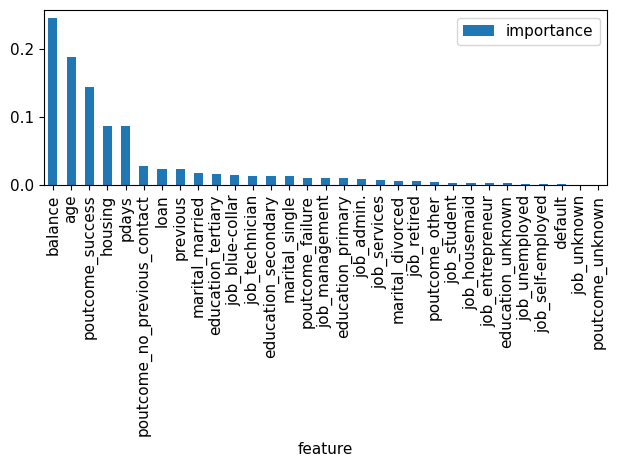

In [ ]:
# --- Guan: Inspect random forest feature importance ---
# AI-assisted code: Yes

# Rank features by their average contribution to reducing impurity.
importance_df = pd.DataFrame({
    "feature": X_train.columns,
    "importance": rf.feature_importances_
})

importance_df = importance_df.sort_values(
    "importance", ascending=False
)

importance_df.plot(kind="bar", x="feature")
plt.tight_layout()
plt.show()

## 31. Tune the single decision tree with grid search
Compare tree depth, minimum leaf size, and minimum impurity decrease using five-fold training cross-validation scored by F1.

In [22]:
# --- Guan: Tune the single decision tree with grid search ---
# AI-assisted code: Yes

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix
)

# Try every combination using 5-fold cross-validation.
param_grid = {
    "max_depth": [3, 5, 10, 20],
    "min_samples_leaf": [20, 50, 100, 200],
    "min_impurity_decrease": [0, 0.0005, 0.001, 0.005, 0.01]
}

gridSearch = GridSearchCV(
    DecisionTreeClassifier(random_state=0),
    param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

# Use only the training data to choose the settings.
gridSearch.fit(X_train, y_train)

print("Best cross-validation F1:", round(gridSearch.best_score_, 4))
print("Parameter values to achieve best F1:", gridSearch.best_params_)

Best cross-validation F1: 0.3015
Parameter values to achieve best F1: {'max_depth': 5, 'min_impurity_decrease': 0.0005, 'min_samples_leaf': 20}


## 32. Evaluate the tuned tree at its default cutoff
Report held-out accuracy, precision, recall, F1, and the confusion matrix for the settings selected by grid search.

In [23]:
# --- Guan: Evaluate the tuned tree at its default cutoff ---
# AI-assisted code: Yes

# The best tree is already fitted on all the training data.
best_clf = gridSearch.best_estimator_

# Predict outcomes for the test customers.
y_pred_test_f1 = best_clf.predict(X_test)

print("Test accuracy:", round(accuracy_score(y_test, y_pred_test_f1), 4))
print("Test precision:", round(precision_score(y_test, y_pred_test_f1, zero_division=0), 4))
print("Test recall:", round(recall_score(y_test, y_pred_test_f1, zero_division=0), 4))
print("Test F1:", round(f1_score(y_test, y_pred_test_f1, zero_division=0), 4))

print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred_test_f1, labels=[0, 1]))

Test accuracy: 0.8912
Test precision: 0.6107
Test recall: 0.1942
Test F1: 0.2947
Confusion matrix:
[[15707   262]
 [ 1705   411]]


## 33. Generate out-of-fold training scores for cutoff selection
Score each training customer with a copy of the tuned tree that did not train on that customer’s fold.

In [24]:
# --- Guan: Generate out-of-fold training scores for cutoff selection ---
# AI-assisted code: Yes

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (
    precision_recall_curve, accuracy_score,
    precision_score, recall_score, f1_score,
    confusion_matrix
)

# Divide the training data into five temporary groups.
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=1
)

# Predict each training customer's probability without training on that row.
cv_probabilities = cross_val_predict(
    clone(best_clf),
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

## 34. Select the cutoff with the highest training cross-validation F1
Compare precision and recall across thresholds; use the higher threshold when F1 scores tie.

In [25]:
# --- Guan: Select the cutoff with the highest training cross-validation F1 ---
# AI-assisted code: Yes

# Calculate precision and recall at each possible cutoff.
precision, recall, thresholds = precision_recall_curve(
    y_train,
    cv_probabilities
)

# The final precision/recall point has no corresponding threshold.
precision = precision[:-1]
recall = recall[:-1]

f1_scores = np.divide(
    2 * precision * recall,
    precision + recall,
    out=np.zeros_like(precision),
    where=(precision + recall) != 0
)

threshold_results = pd.DataFrame({
    "Threshold": thresholds,
    "Precision": precision,
    "Recall": recall,
    "F1": f1_scores
})

# If F1 scores tie, choose the higher threshold.
threshold_results = threshold_results.sort_values(
    ["F1", "Threshold"],
    ascending=[False, False]
)

best_threshold = float(threshold_results.iloc[0]["Threshold"])

print("Selected threshold:", best_threshold)
print("Best training cross-validation F1:",
      round(threshold_results.iloc[0]["F1"], 4))

# These values are proportions: 0.60 means 60%.
display(threshold_results.head(10).round(4))

Selected threshold: 0.2272108843537415
Best training cross-validation F1: 0.3754


,Threshold,Precision,Recall,F1
10,0.2272,0.4106,0.3457,0.3754
11,0.2434,0.4181,0.3284,0.3679
12,0.2442,0.4427,0.3104,0.3649
13,0.2500,0.4688,0.2931,0.3607
14,0.3207,0.5037,0.2789,0.3590
15,0.3219,0.5118,0.2657,0.3498
16,0.3373,0.5226,0.2518,0.3399
9,0.1179,0.2802,0.4248,0.3377
17,0.3397,0.5295,0.2433,0.3334
18,0.3460,0.5492,0.2323,0.3265


## 35. Compare default and F1-tuned tree cutoffs on the test set
Refit the selected tree, apply both prediction rules to the same held-out customers, and compare detection rates, errors, and call-list size.

In [26]:
# --- Guan: Compare default and F1-tuned tree cutoffs on the test set ---
# AI-assisted code: Yes

# Fit the selected tree settings on all the training data.
final_tree = clone(best_clf)
final_tree.fit(X_train, y_train)

test_probabilities = final_tree.predict_proba(X_test)[:, 1]

# Compare the original prediction rule with the selected threshold.
default_predictions = final_tree.predict(X_test)
tuned_predictions = (
    test_probabilities >= best_threshold
).astype(int)

def evaluate_threshold(y_true, predictions):
    tn, fp, fn, tp = confusion_matrix(
        y_true, predictions, labels=[0, 1]
    ).ravel()

    return {
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1": f1_score(y_true, predictions, zero_division=0),
        "FPR": fp / (fp + tn) if fp + tn else 0,
        "Selected fraction": np.mean(predictions == 1)
    }

comparison = pd.DataFrame({
    "Default cutoff": evaluate_threshold(
        y_test, default_predictions
    ),
    "F1-tuned cutoff": evaluate_threshold(
        y_test, tuned_predictions
    )
}).T

display(comparison.round(4))

print("Confusion matrix with the tuned cutoff:")
print(confusion_matrix(y_test, tuned_predictions, labels=[0, 1]))

,Accuracy,Precision,Recall,F1,FPR,Selected fraction
Default cutoff,0.8912,0.6107,0.1942,0.2947,0.0164,0.0372
F1-tuned cutoff,0.8649,0.4134,0.3686,0.3897,0.0693,0.1043


Confusion matrix with the tuned cutoff:
[[14862  1107]
 [ 1336   780]]
